# Task 3 — spending prediction models

Round 1 compares original and combined EDA artifacts on one stratified 80/20 split. The target is next-30-day THB spending. The competition describes NMAE but the supplied documents omit its denominator. Every saved evaluation therefore uses **MAE_thb**; it is not an official NMAE score. Existing artifacts load on rerun. Preprocessing is fitted inside each saved Pipeline.

## 1. Load saved datasets by their JSON cards

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "src" / "pipeline" / "save_data.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
SRC = ROOT / "src"

import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.inspection import permutation_importance
from src.pipeline.random_seed import set_seed
from src.pipeline.save_model import save_model
from src.pipeline.evaluate_model import evaluate_model
from src.pipeline.read_evalutate_summarize import read_evaluation_index

SEED = set_seed()
ID, TARGET = "player_id", "spending_30d"
DATA_NAMES = {"original": "eda_original_v1", "combined": "eda_combined_v1"}
sns.set_theme(style="whitegrid")

def load_dataset(name):
    card_path = SRC / "task3" / "data" / "eda" / f"{name}.json"
    card = json.loads(card_path.read_text(encoding="utf-8"))
    assert card["name"] == name and card["task"] == "task3"
    def read_split(split):
        path = SRC / card["splits"][split]["path"]
        return pd.read_parquet(path) if card["format"] == "parquet" else pd.read_csv(path)
    return card, read_split("train"), read_split("test")

original_card, train_original, test_original = load_dataset(DATA_NAMES["original"])
combined_card, train_combined, test_combined = load_dataset(DATA_NAMES["combined"])
assert train_original[ID].equals(train_combined[ID])
assert test_original[ID].equals(test_combined[ID])
assert train_original[TARGET].equals(train_combined[TARGET])
raw_features = test_original.columns.drop(ID).tolist()
combined_features = test_combined.columns.drop(ID).tolist()
engineered_features = [c for c in combined_features if c not in raw_features]
assert len(raw_features) == 32 and len(engineered_features) == 16
assert combined_features[:len(raw_features)] == raw_features
assert train_original[raw_features].equals(train_combined[raw_features])
assert test_original[raw_features].equals(test_combined[raw_features])
print("Original/combined features:", len(raw_features), len(combined_features))
print("Train/Test rows:", len(train_original), len(test_original))

Original/combined features: 32 48
Train/Test rows: 104000 25889


## 2. Create one matched development/validation split

In [2]:
y = train_original[TARGET].astype(float)
assert y.notna().all() and (y >= 0).all()
# Preserve zero spenders and several positive spending ranges in both portions.
spending_band = pd.cut(y, bins=[-1, 0, 100, 1000, 10000, 50000, np.inf],
                       labels=False)
assert spending_band.notna().all() and spending_band.value_counts().min() > 100
dev_idx, valid_idx = train_test_split(
    np.arange(len(y)), test_size=.20, stratify=spending_band, random_state=SEED)
X_dev = {
    "original": train_original.iloc[dev_idx][raw_features],
    "combined": train_combined.iloc[dev_idx][combined_features],
}
X_valid = {
    "original": train_original.iloc[valid_idx][raw_features],
    "combined": train_combined.iloc[valid_idx][combined_features],
}
y_dev, y_valid = y.iloc[dev_idx], y.iloc[valid_idx]
assert X_dev["original"].index.equals(X_dev["combined"].index)
assert X_valid["original"].index.equals(X_valid["combined"].index)
assert y_dev.index.intersection(y_valid.index).empty
display(pd.DataFrame({
    "development": spending_band.iloc[dev_idx].value_counts().sort_index(),
    "validation": spending_band.iloc[valid_idx].value_counts().sort_index(),
    "development_pct": spending_band.iloc[dev_idx].value_counts(normalize=True).sort_index().mul(100),
    "validation_pct": spending_band.iloc[valid_idx].value_counts(normalize=True).sort_index().mul(100),
}).round(2))
print("Validation zero share:", round((y_valid == 0).mean(), 4))

,development,validation,development_pct,validation_pct
spending_30d,,,,
0,40039,10010,48.12,48.12
1,2006,501,2.41,2.41
2,11291,2822,13.57,13.57
3,18608,4652,22.37,22.37
4,4470,1118,5.37,5.38
5,6786,1697,8.16,8.16


Validation zero share: 0.4812


## 3. Preprocessing and artifact reuse

The four numeric-coded nominal fields are one-hot encoded. Other numeric inputs use development-fitted median imputation with missing indicators. This preserves raw missingness without fitting on Test. Each saved model includes its fitted preprocessing.

In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

nominal_cols = ["primary_game", "platform", "seasonal_spending_pattern", "segment"]
assert set(nominal_cols) <= set(raw_features)
def make_preprocessor(dataset="original"):
    assert dataset in DATA_NAMES
    cols = raw_features if dataset == "original" else combined_features
    numeric_cols = [c for c in cols if c not in nominal_cols]
    return ColumnTransformer([
        ("numeric", SimpleImputer(strategy="median", add_indicator=True), numeric_cols),
        ("nominal", Pipeline([
            ("impute", SimpleImputer(strategy="constant", fill_value=-1)),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), nominal_cols),
    ], remainder="drop", sparse_threshold=0)

SAVE_DIR = SRC / "task3" / "save"
def model_paths(name):
    return SAVE_DIR / f"{name}.joblib", SAVE_DIR / f"{name}.json", SAVE_DIR / f"{name}-evaluation.json"

def load_model(name):
    model_path, card_path, _ = model_paths(name)
    card = json.loads(card_path.read_text(encoding="utf-8"))
    assert card["model_path"] == f"task3/save/{name}.joblib"
    return joblib.load(model_path)

def score_validation(model, dataset):
    pred = np.asarray(model.predict(X_valid[dataset]), dtype=float).reshape(-1)
    return pred, float(mean_absolute_error(y_valid, pred))

def saved_result(name, dataset="original"):
    model_path, card_path, evaluation_path = model_paths(name)
    if not any(p.exists() for p in (model_path, card_path, evaluation_path)):
        return None
    if not model_path.exists() or not card_path.exists():
        raise RuntimeError(f"Incomplete model artifact for {name}")
    model_card = json.loads(card_path.read_text(encoding="utf-8"))
    expected = DATA_NAMES[dataset]
    if model_card["data_name"] != expected:
        raise ValueError(f"{name} links to the wrong dataset")
    if not evaluation_path.exists():
        pred, mae = score_validation(load_model(name), dataset)
        result = evaluate_model(
            task=3, name=name, score=mae, metric_name="MAE_thb",
            higher_is_better=False,
            card={"split": "stratified holdout 20%", "seed": SEED,
                  "note": "MAE proxy; official NMAE denominator unavailable"})
        print("Recorded missing evaluation:", name)
        return result
    result = json.loads(evaluation_path.read_text(encoding="utf-8"))
    assert result["metric"] == "MAE_thb" and result["data_name"] == expected
    print(f"Loaded {name}: MAE = {result['score']:.2f} THB")
    return result

def record_model(name, model, idea, dataset="original"):
    save_model(
        task=3, name=name, model=model, data_name=DATA_NAMES[dataset],
        card={"idea": idea, "seed": SEED, "split": "stratified 80/20",
              "metric_note": "MAE_thb proxy; official NMAE denominator unavailable"})
    pred, mae = score_validation(model, dataset)
    result = evaluate_model(
        task=3, name=name, score=mae, metric_name="MAE_thb",
        higher_is_better=False,
        card={"split": "held-out validation 20%", "seed": SEED,
              "note": "MAE proxy; official NMAE denominator unavailable"})
    print(f"Trained {name}: MAE = {result['score']:.2f} THB")
    return result

## 4. Round 1 — median reference and HGB

In [4]:
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor

name = "t3_dummy_original_v1"
if saved_result(name) is None:
    model = DummyRegressor(strategy="median")
    model.fit(X_dev["original"], y_dev)
    record_model(name, model, "Global median spending reference")

Loaded t3_dummy_original_v1: MAE = 10431.34 THB


In [5]:
name = "t3_hgb_original_v1"
if saved_result(name) is None:
    model = Pipeline([
        ("preprocess", make_preprocessor("original")),
        ("regressor", HistGradientBoostingRegressor(
            loss="absolute_error", max_iter=220, learning_rate=.07,
            max_leaf_nodes=31, min_samples_leaf=40,
            early_stopping=True, random_state=SEED)),
    ])
    model.fit(X_dev["original"], y_dev)
    record_model(name, model, "HGB absolute-error regression on original features")

Loaded t3_hgb_original_v1: MAE = 2959.57 THB


In [6]:
name = "t3_hgb_combined_v1"
if saved_result(name, "combined") is None:
    model = Pipeline([
        ("preprocess", make_preprocessor("combined")),
        ("regressor", HistGradientBoostingRegressor(
            loss="absolute_error", max_iter=220, learning_rate=.07,
            max_leaf_nodes=31, min_samples_leaf=40,
            early_stopping=True, random_state=SEED)),
    ])
    model.fit(X_dev["combined"], y_dev)
    record_model(name, model, "Matched HGB plus 16 behavior features", "combined")

Loaded t3_hgb_combined_v1: MAE = 2997.50 THB


### LightGBM with the same preprocessing and an absolute-error objective

In [7]:
from lightgbm import LGBMRegressor

name = "t3_lgb_original_v1"
if saved_result(name) is None:
    model = Pipeline([
        ("preprocess", make_preprocessor("original")),
        ("regressor", LGBMRegressor(
            objective="regression_l1", n_estimators=400,
            learning_rate=.05, num_leaves=31, min_child_samples=50,
            reg_lambda=1., verbosity=-1, random_state=SEED, n_jobs=4)),
    ])
    model.fit(X_dev["original"], y_dev)
    record_model(name, model, "LightGBM absolute-error regression on original features")

Loaded t3_lgb_original_v1: MAE = 2960.34 THB


In [8]:
name = "t3_lgb_combined_v1"
if saved_result(name, "combined") is None:
    model = Pipeline([
        ("preprocess", make_preprocessor("combined")),
        ("regressor", LGBMRegressor(
            objective="regression_l1", n_estimators=400,
            learning_rate=.05, num_leaves=31, min_child_samples=50,
            reg_lambda=1., verbosity=-1, random_state=SEED, n_jobs=4)),
    ])
    model.fit(X_dev["combined"], y_dev)
    record_model(name, model, "Matched LightGBM plus 16 behavior features", "combined")

Loaded t3_lgb_combined_v1: MAE = 2957.98 THB


## 5. Rank Round 1 on the matched validation rows

Only these five named models enter this table. MAE is in THB and lower is better; it is not the official NMAE. The positive and zero slices explain which population contributes to the error.

,name,dataset,MAE_thb,MAE_zero,MAE_positive,negative_predictions
0,t3_lgb_combined_v1,combined,2957.98,1733.35,4094.08,480
1,t3_hgb_original_v1,original,2959.57,1733.18,4097.30,330
2,t3_lgb_original_v1,original,2960.34,1741.54,4091.02,430
3,t3_hgb_combined_v1,combined,2997.50,1730.54,4172.87,309
4,t3_dummy_original_v1,original,10431.34,78.61,20035.67,0


Best Round 1 model: t3_lgb_combined_v1


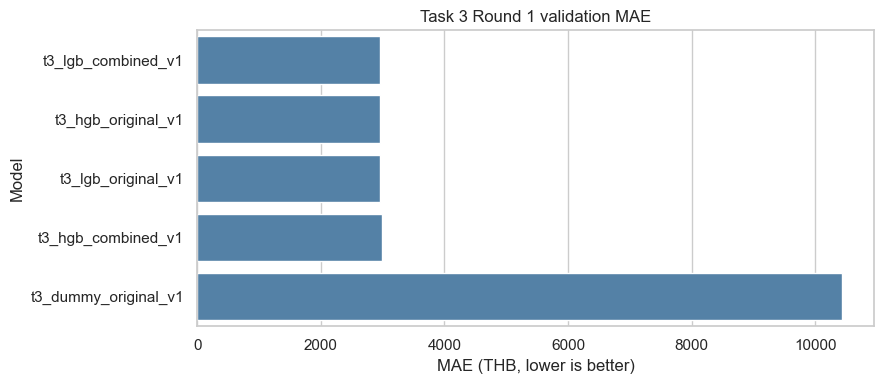

,model,original_MAE,combined_MAE,delta_combined_minus_original
0,HGB,2959.57,2997.50,37.93
1,LightGBM,2960.34,2957.98,-2.36


In [9]:
round1_names = [
    "t3_dummy_original_v1", "t3_hgb_original_v1",
    "t3_hgb_combined_v1", "t3_lgb_original_v1", "t3_lgb_combined_v1",
]
index = read_evaluation_index(3)["evaluations"]
assert all(name in index and index[name]["metric"] == "MAE_thb" for name in round1_names)
ranking_rows = []
for name in round1_names:
    model_card = json.loads(model_paths(name)[1].read_text(encoding="utf-8"))
    dataset = next(k for k, v in DATA_NAMES.items() if v == model_card["data_name"])
    pred, mae = score_validation(load_model(name), dataset)
    assert abs(mae - index[name]["score"]) < 1e-8
    zero_mask = y_valid.to_numpy() == 0
    ranking_rows.append({
        "name": name, "dataset": dataset, "MAE_thb": mae,
        "MAE_zero": float(np.abs(pred[zero_mask]).mean()),
        "MAE_positive": float(np.abs(y_valid.to_numpy()[~zero_mask] - pred[~zero_mask]).mean()),
        "negative_predictions": int((pred < 0).sum()),
    })
ranking = pd.DataFrame(ranking_rows).sort_values("MAE_thb").reset_index(drop=True)
display(ranking.round(2))
print("Best Round 1 model:", ranking.iloc[0]["name"])
fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(data=ranking, x="MAE_thb", y="name", color="steelblue", ax=ax)
ax.set(title="Task 3 Round 1 validation MAE", xlabel="MAE (THB, lower is better)",
       ylabel="Model")
plt.tight_layout()
plt.show()
matched = pd.DataFrame([
    {"model": family, "original_MAE": index[original]["score"],
     "combined_MAE": index[combined]["score"],
     "delta_combined_minus_original": index[combined]["score"] - index[original]["score"]}
    for family, original, combined in [
        ("HGB", "t3_hgb_original_v1", "t3_hgb_combined_v1"),
        ("LightGBM", "t3_lgb_original_v1", "t3_lgb_combined_v1"),
    ]
])
display(matched.round(2))

## 6. Inspect the leading model

Winner: t3_lgb_combined_v1 | MAE: 2957.98 THB


,rows,actual_median,prediction_median,MAE_thb
spending_band,,,,
zero,10010,0.00,0.00,1733.35
1–1k,3323,294.64,0.00,288.09
1k–10k,4652,2524.26,2129.85,706.60
10k–50k,1118,31410.64,31490.05,4589.21
50k+,1697,86584.02,80748.34,20506.72


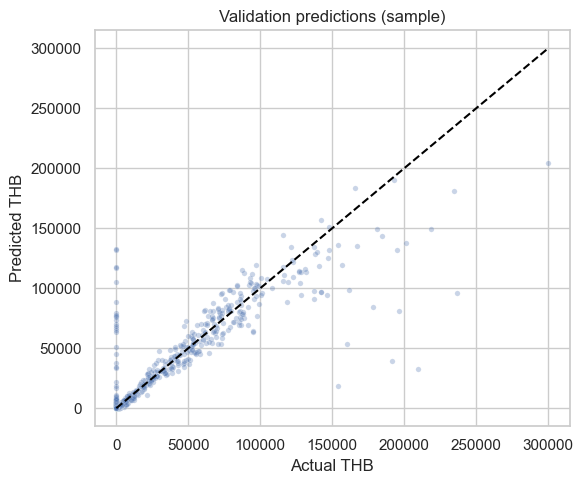

In [10]:
winner_name = ranking.iloc[0]["name"]
winner_dataset = ranking.iloc[0]["dataset"]
winner_model = load_model(winner_name)
winner_pred, winner_mae = score_validation(winner_model, winner_dataset)
print("Winner:", winner_name, "| MAE:", round(winner_mae, 2), "THB")
diagnostic = pd.DataFrame({
    "actual": y_valid.to_numpy(), "prediction": winner_pred,
    "absolute_error": np.abs(y_valid.to_numpy() - winner_pred),
})
diagnostic["spending_band"] = pd.cut(
    diagnostic["actual"], bins=[-1, 0, 1000, 10000, 50000, np.inf],
    labels=["zero", "1–1k", "1k–10k", "10k–50k", "50k+"])
display(diagnostic.groupby("spending_band", observed=True).agg(
    rows=("actual", "size"), actual_median=("actual", "median"),
    prediction_median=("prediction", "median"),
    MAE_thb=("absolute_error", "mean")).round(2))
fig, ax = plt.subplots(figsize=(6, 5))
sns.scatterplot(data=diagnostic.sample(n=2500, random_state=SEED),
                x="actual", y="prediction", alpha=.3, s=15, ax=ax)
ax.plot([0, 300000], [0, 300000], color="black", linestyle="--")
ax.set(title="Validation predictions (sample)", xlabel="Actual THB", ylabel="Predicted THB")
plt.tight_layout()
plt.show()

Loaded permutation importance: t3_lgb_combined_v1


,feature,MAE_increase,std
0,prev_month_spending,6407.10,1.83
1,historical_spending,2700.42,156.86
2,segment,1429.75,150.31
3,vip_status,559.53,71.48
4,days_since_last_purchase,486.96,71.59
5,is_premium_member,208.90,22.57
6,seasonal_spending_pattern,146.04,39.92
7,games_played,115.66,0.67
8,total_transactions,34.19,6.55
9,purchase_frequency,17.68,8.23


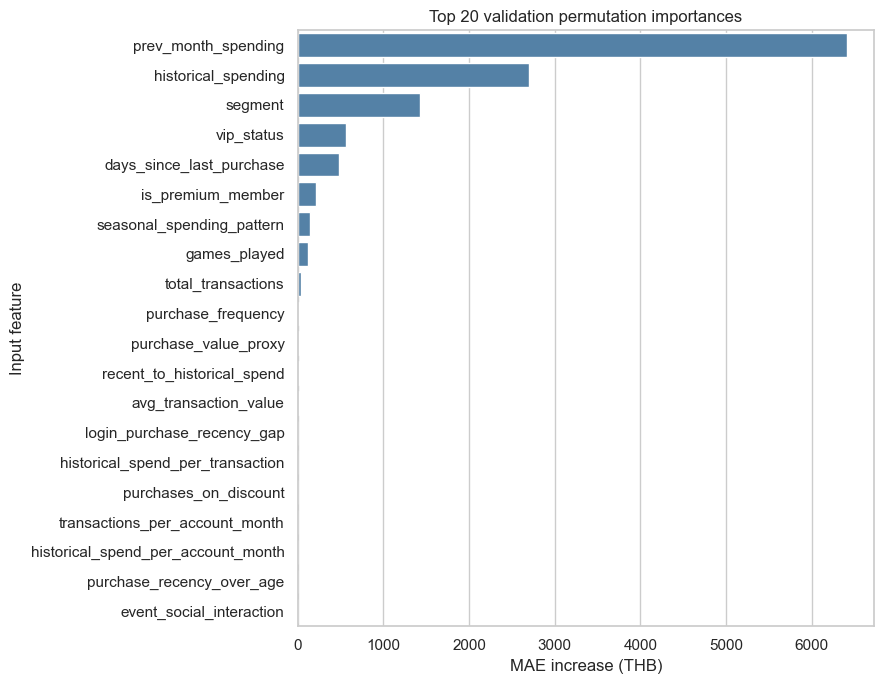

In [11]:
winner_train = train_original if winner_dataset == "original" else train_combined
winner_features = raw_features if winner_dataset == "original" else combined_features
importance_path = SRC / "task3" / "models" / ".cache" / f"{winner_name}-permutation-v1.json"
model_path = model_paths(winner_name)[0]
data_card = original_card if winner_dataset == "original" else combined_card
cache_key = {"model_mtime_ns": model_path.stat().st_mtime_ns,
             "data_created_at": data_card["created_at"], "seed": SEED,
             "rows": 1200, "repeats": 2}
cached = json.loads(importance_path.read_text(encoding="utf-8")) if importance_path.exists() else None
if cached is not None and cached.get("key") == cache_key:
    feature_ranking = pd.DataFrame(cached["ranking"])
    print("Loaded permutation importance:", winner_name)
else:
    sample_idx = pd.Series(valid_idx).sample(n=1200, random_state=SEED).to_numpy()
    sample_X = winner_train.iloc[sample_idx][winner_features]
    sample_y = y.iloc[sample_idx]
    # Scoring by negative MAE, matching the ranking direction.
    importance = permutation_importance(
        winner_model, sample_X, sample_y, scoring="neg_mean_absolute_error",
        n_repeats=2, random_state=SEED, n_jobs=1)
    feature_ranking = pd.DataFrame({
        "feature": winner_features, "MAE_increase": importance.importances_mean,
        "std": importance.importances_std,
    }).sort_values("MAE_increase", ascending=False).reset_index(drop=True)
    importance_path.parent.mkdir(parents=True, exist_ok=True)
    importance_path.write_text(
        json.dumps({"key": cache_key, "ranking": feature_ranking.to_dict("records")}, indent=2),
        encoding="utf-8")
    print("Computed permutation importance:", winner_name)
display(feature_ranking.round(2))
fig, ax = plt.subplots(figsize=(9, 7))
sns.barplot(data=feature_ranking.head(20), x="MAE_increase", y="feature",
            color="steelblue", ax=ax)
ax.set(title="Top 20 validation permutation importances",
       xlabel="MAE increase (THB)", ylabel="Input feature")
plt.tight_layout()
plt.show()

### Round 1 interpretation

The tables above compare five named models on identical validation rows. The winner is only a provisional **MAE_thb** leader; its margin over the next model is small. The target is zero-heavy, so inspect zero and positive spending errors separately. Some tree predictions are slightly negative even though spending cannot be; keep the raw-model MAE honest here and handle nonnegative inference explicitly before a final submission. NMAE remains uncomputed until the organizer's denominator is known.